# Figure 3: EnsIOL versus MCMC catalog growth for test case 14

Accuracy (RMS error) and data misfit (nRMS) against the number of forward model calls spent on growing the catalog, for EnsIOL and the MCMC baseline, on the same test case as Figure 2.

Runs both methods from the prior catalog (no saved results are loaded), through the same `EnsIOLvsMCMC` class that `scripts/run_ensiol_vs_mcmc.py` uses:

* **EnsIOL** is scored after every iteration: the catalog at that stage is the original catalog plus the members added so far, and each added member costs one forward call.
* **MCMC** (pCN, 50 chains, up to 20,000 calls, Gaussian prior with the catalog's own mean and covariance) is scored at fixed call budgets. Accepted states that are non-redundant join the catalog under the same distance rule as EnsIOL's candidates.
* Every point is the same single backward EnsCGP update on the members of that catalog closest to the observation.

Running time is a few minutes on a laptop (EnsIOL, then 20,000 MCMC forward calls, then about 70 scored catalogs).

In [1]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import ensiol
from ensiol import ExperimentContext, EnsIOLConfig, ScoringConfig

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = REPO / "data" / "kilauea"        # prior catalog, grids and the synthetic test set
FIG_DIR = REPO / "figures"                  # figures are written here
FIG_DIR.mkdir(exist_ok=True)

from ensiol.baselines import PCNConfig
from ensiol.experiments.mcmc_comparison import EnsIOLvsMCMC, cost_series
from ensiol.plotting import ComparisonStyle, plot_comparison

# Select the inline backend after the imports, so figures display in the notebook
%matplotlib inline

## 1. Settings

In [2]:
SAMPLE_IDX = 14
MCMC_MAX_CALLS = 20000
SCORING = ScoringConfig(exclude_halfspace=True, nrms_convention="MoR")   # manuscript conventions
NRMS_KEY = "nrms_" + SCORING.nrms_convention.lower()
OUT_BASENAME = f"fig3_ensiol_vs_mcmc_sample_{SAMPLE_IDX:03d}"

## 2. Run both methods

In [3]:
ctx = ExperimentContext.from_data_dir(str(DATA_DIR), with_test=True, scoring=SCORING,
                                       pcn=PCNConfig(max_calls=MCMC_MAX_CALLS))
exp = EnsIOLvsMCMC(ctx, str(REPO / "outputs" / "notebooks" / "fig3"),
                   ensiol_dir=None,                 # rerun EnsIOL rather than reuse saved additions
                   ensiol_budgets="iterations",     # EnsIOL scored after every iteration
                   make_figures=False)
rec = exp.run_item(SAMPLE_IDX)
print(f"EnsIOL: {int(rec['ensiol_total_calls'])} calls | "
      f"MCMC: {int(rec['mcmc_total_calls'])} calls, {int(rec['mcmc_n_added_total'])} members kept "
      f"(acceptance in second half {np.mean(rec['mcmc_acc'][len(rec['mcmc_acc']) // 2:]):.2f}) | {rec['runtime_s'] / 60:.1f} min")

prior catalog: 10000 members | 54 layers | 37 freqs | d_min = 1.0695
EnsIOL: 1931 calls | MCMC: 20000 calls, 760 members kept (acceptance in second half 0.12) | 2.6 min


### Check against the manuscript

The text reports for this case: EnsIOL RMS 0.35 and nRMS 1.04 after 1,931 calls; MCMC 0.91 and 3.42 after 2,000 calls and 0.67 and 1.92 after 20,000. Both nRMS conventions are shown so the one behind each number is visible.

In [4]:
def at(method, calls):
    """Scores of `method` at the last checkpoint not above `calls` forward calls."""
    s = cost_series(rec, method, "iterations")
    j = int(np.searchsorted(s["calls"], calls, side="right")) - 1
    return int(s["calls"][j]), s["rms"][j], s["nrms_mor"][j], s["nrms_rom"][j]

print(f"{'':28s}{'calls':>7}{'RMS':>8}{'nRMS MoR':>10}{'nRMS RoM':>10}   manuscript (RMS, nRMS)")
for label, method, calls, ms in [("EnsIOL, final", "ensiol", 10 ** 9, (0.35, 1.04)),
                                 ("MCMC, 2,000 calls", "mcmc", 2000, (0.91, 3.42)),
                                 ("MCMC, 20,000 calls", "mcmc", 20000, (0.67, 1.92))]:
    c, rms, mor, rom = at(method, calls)
    print(f"{label:28s}{c:7d}{rms:8.2f}{mor:10.2f}{rom:10.2f}   {ms}")

                              calls     RMS  nRMS MoR  nRMS RoM   manuscript (RMS, nRMS)
EnsIOL, final                  1931    0.35      1.04      1.06   (0.35, 1.04)
MCMC, 2,000 calls              2000    0.91      3.42      3.69   (0.91, 3.42)
MCMC, 20,000 calls            20000    0.67      1.92      2.16   (0.67, 1.92)


## 3. Figure

All styling lives in `ComparisonStyle` (sizes in inches and points, so the figure is built at its printed size: 3.5 in for one column of a two-column IEEE journal, 7.16 in for full width). Use `STYLE.but(...)` to change a setting and rerun only this cell.

* `layout`: `"horizontal"` puts the two panels side by side, `"vertical"` stacks them with a shared x axis. For a single column use `layout="vertical", fig_width=3.5, panel_height=1.8`.
* `original_style`: `"marker"` draws the original catalog as a grey square left of the first budget, `"line"` as a dotted horizontal line, `None` omits it.
* `legend_mode`: `"below"` (one shared legend under the figure) or `"inside"` (in panel `legend_panel`).
* `annotate_done` labels EnsIOL's stopping line, `annotate_kept` adds how many MCMC calls produced catalog members.

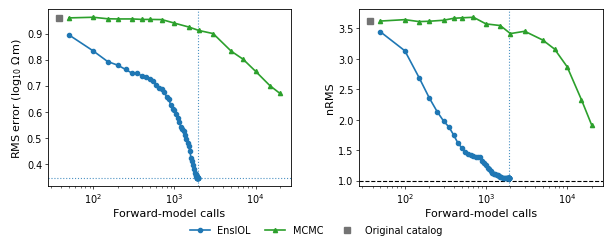

saved figures/fig3_ensiol_vs_mcmc_sample_014.pdf, figures/fig3_ensiol_vs_mcmc_sample_014.png


In [5]:
STYLE = ComparisonStyle()          # defaults reproduce the manuscript figure
iol, mcm = cost_series(rec, "ensiol", "iterations"), cost_series(rec, "mcmc")
fig = plot_comparison(iol, mcm, int(rec["ensiol_total_calls"]), int(rec["mcmc_n_added_total"]),
                      int(rec["mcmc_total_calls"]), STYLE, NRMS_KEY)
for ext in STYLE.formats:
    fig.savefig(FIG_DIR / f"{OUT_BASENAME}.{ext}", dpi=STYLE.dpi, bbox_inches="tight", pad_inches=0.02)
plt.show()
print("saved", ", ".join(f"figures/{OUT_BASENAME}.{e}" for e in STYLE.formats))

## Notes

* **Both curves use the same evaluator:** one single backward EnsCGP update per catalog and budget, with the same seed. They differ only in how the catalog was grown.
* **The x positions are actual forward calls.** For MCMC these can be up to 50 calls above the nominal budget, because a round of 50 chains finishes as a unit. EnsIOL's points sit at its own cumulative call counts after each iteration, and its last point is its stopping point.
* **MCMC is compared only as a catalog-growth method.** The cost of augmenting a catalog is the number of forward model calls made to build it: the number of members added for EnsIOL, the total number of sampler calls for MCMC.
* **Reference lines.** The vertical dotted line marks EnsIOL's stopping point, the horizontal dotted line (left panel) marks EnsIOL's final RMS error, and the dashed line (right panel) marks nRMS = 1. They are not in the legend.
* **nRMS convention.** The right panel uses `NRMS_KEY`; the default `"nrms_mor"` is the misfit of the mean of the members' simulated responses. The record holds both conventions.